# FIONA vs glworia: validating the inference pipeline

Before using the pipeline on new lens models, we check it against the method of Cheung et al. (2024), hereafter C24, whose code is public as [`glworia`](https://github.com/mhycheung/glworia).

Both pipelines analyze exactly the same data:

- the same GW150914-like injection, a nonspinning $30+30\,M_\odot$ binary at 500 Mpc, in simulated H1 and L1 O4 noise, with one fixed noise realization;
- the same priors, including a log-uniform prior on the lens mass $M_{Lz}$ over $[0.1, 2000]\,M_\odot$;
- the same sampler, `dynesty` through `bilby`, with 1000 live points.

The only difference is how the amplification factor $F(w, y, x_c)$ is computed. This pipeline interpolates a table built with FIONA, while `glworia` interpolates its own time-domain table. If both evaluations are accurate, the posteriors should agree to within sampling noise.

This notebook uses the posterior samples shipped in `results/posteriors/` and the run statistics in `results/run_summary.json`.

In [1]:
import json

import corner
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from infer_with_fiona import paths
from infer_with_fiona import posteriors as P

## The four benchmarks

C24 defines one strongly lensed case and three weakly lensed ones, all for a cored isothermal sphere (CIS) lens with $M_{Lz} = 100\,M_\odot$. Here $y$ is the source position and $x_c$ the core radius, both in units of the Einstein radius.

In [2]:
CASES = {  # name: (y, x_c, colour)
    'strong, y = 0.3': (0.3, 0.02, 'tab:red'),
    'weak, y = 1':     (1.0, 0.2, 'tab:blue'),
    'weak, y = 2':     (2.0, 0.2, 'tab:orange'),
    'weak, y = 3':     (3.0, 0.2, 'tab:green'),
}

runs = {}
for case, (y, xc, _) in CASES.items():
    fiona, _ = P.load_fiona(P.fiona_label('CIS', y, xc))
    glworia, _ = P.load_glworia(P.glworia_name(y, xc))
    runs[case] = dict(fiona=fiona, glworia=glworia)

{case: (len(r['fiona']['y']), len(r['glworia']['y'])) for case, r in runs.items()}   # posterior samples per run

{'strong, y = 0.3': (6644, 6323),
 'weak, y = 1': (6622, 6699),
 'weak, y = 2': (6285, 6113),
 'weak, y = 3': (6498, 6368)}

## 1. Lens-parameter posteriors

The filled contours are this pipeline and the gray lines are `glworia`, at 68% and 95%. Black lines mark the injected values.

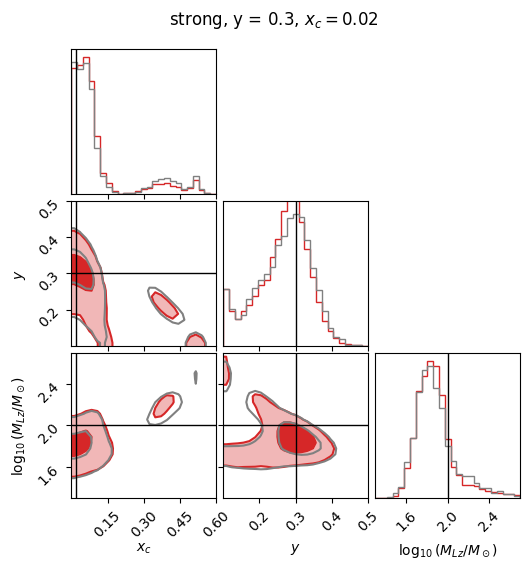

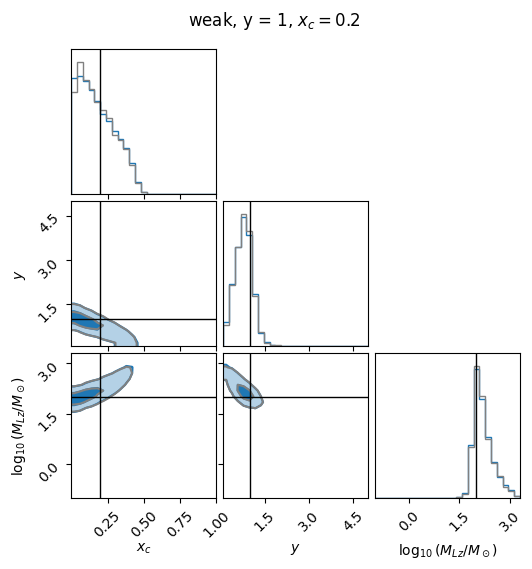

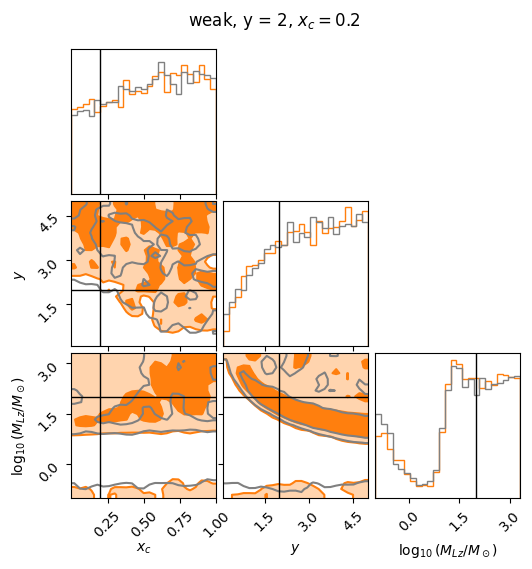

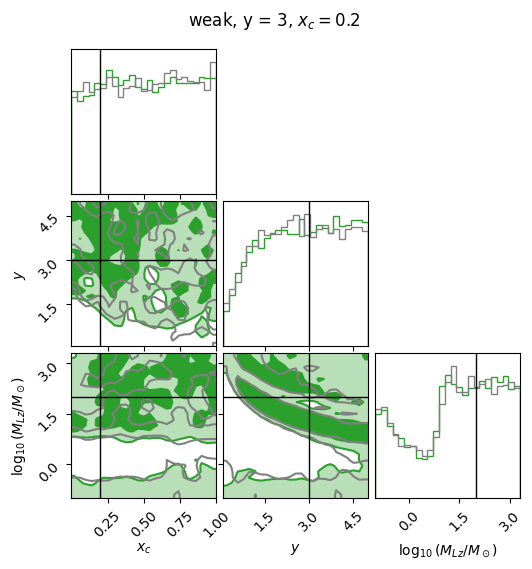

In [3]:
def lens_samples(post):
    return np.column_stack([post['lp'], post['y'], np.log10(post['MLz'])])


LABELS = [r'$x_c$', r'$y$', r'$\log_{10}(M_{Lz}/M_\odot)$']
STYLE = dict(labels=LABELS, levels=(1 - np.exp(-0.5), 1 - np.exp(-2)), bins=25, smooth=0.9,
             plot_density=False, plot_datapoints=False, max_n_ticks=4)

for case, (y, xc, color) in CASES.items():
    sf, sg = lens_samples(runs[case]['fiona']), lens_samples(runs[case]['glworia'])
    rng = [(0, 0.6), (0.1, 0.5), (1.3, 2.7)] if y < 0.5 else [(0, 1), (0.1, 5), (-1, np.log10(2000))]
    fig = plt.figure(figsize=(5.5, 5.5))
    corner.corner(sf, fig=fig, color=color, fill_contours=True, range=rng, hist_kwargs=dict(density=True), **STYLE)
    corner.corner(sg, fig=fig, color='gray', no_fill_contours=True, range=rng, hist_kwargs=dict(density=True), **STYLE)
    corner.overplot_lines(fig, [xc, y, 2.0], color='black', lw=1)
    fig.suptitle(f'{case}, $x_c = {xc:g}$', y=1.02)
    plt.show()

In the strongly lensed case the data pin down all three lens parameters. In the weakly lensed cases the signal constrains $M_{Lz}$ only in combination with $y$, so the two are correlated and the marginal $M_{Lz}$ posterior partly reflects the prior. Either way, the two pipelines trace the same shapes.

## 2. Agreement across all 14 parameters

For each sampled parameter we compare the posterior medians in units of the mean posterior width, $\sigma = \sqrt{(\sigma_{\rm FIONA}^2 + \sigma_{\rm glworia}^2)/2}$, and the ratio of the widths. Independent runs of the same sampler differ by a few hundredths of $\sigma$ from sampling noise alone.

In [4]:
PARAMS = P.search_order('CIS')

rows = []
for case, r in runs.items():
    for k in PARAMS:
        a, b = r['fiona'][k], r['glworia'][k]
        if k == 'MLz':
            a, b = np.log10(a), np.log10(b)
        sigma = np.sqrt((a.std() ** 2 + b.std() ** 2) / 2)
        rows.append(dict(case=case, parameter=k, delta_median=(np.median(a) - np.median(b)) / sigma,
                         width_ratio=b.std() / a.std()))
agreement = pd.DataFrame(rows)

agreement.groupby('case', sort=False).agg(
    max_abs_delta_median=('delta_median', lambda d: d.abs().max()),
    min_width_ratio=('width_ratio', 'min'),
    max_width_ratio=('width_ratio', 'max'),
).style.format(precision=3)

,max_abs_delta_median,min_width_ratio,max_width_ratio
case,,,
"strong, y = 0.3",0.057,0.970,1.137
"weak, y = 1",0.025,0.978,1.017
"weak, y = 2",0.036,0.964,1.044
"weak, y = 3",0.051,0.986,1.020


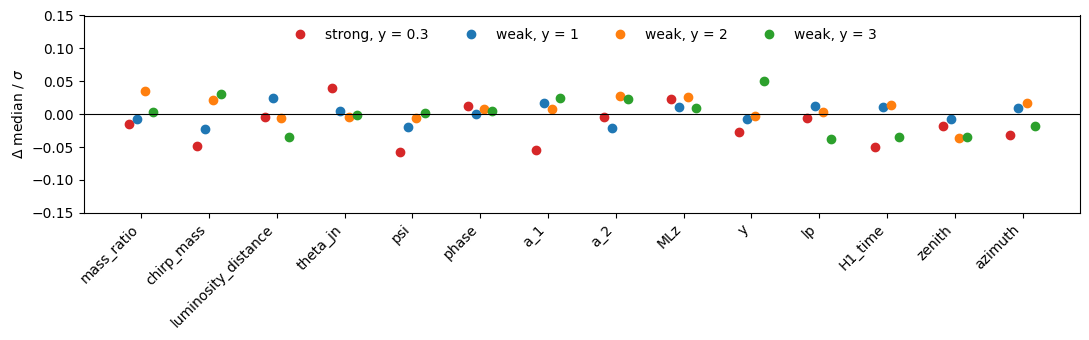

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.5))
for i, (case, (_, _, color)) in enumerate(CASES.items()):
    d = agreement[agreement.case == case]
    ax.plot(np.arange(len(PARAMS)) + 0.12 * (i - 1.5), d.delta_median, 'o', color=color, label=case)
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks(range(len(PARAMS)), PARAMS, rotation=45, ha='right')
ax.set_ylabel(r'$\Delta$ median / $\sigma$')
ax.set_ylim(-0.15, 0.15)
ax.legend(ncol=4, frameon=False, loc='upper center')
plt.tight_layout()

The widths agree to within about 6%, with one exception visible in the table: in the strongly lensed case, `glworia`'s core-radius posterior (`lp`) is wider. That posterior piles up against the prior edge at $x_c = 0$.

In [6]:
agreement.loc[agreement.width_ratio.sub(1).abs().nlargest(3).index].style.format(precision=3).hide(axis='index')

case,parameter,delta_median,width_ratio
"strong, y = 0.3",lp,-0.006,1.137
"strong, y = 0.3",MLz,0.023,1.065
"strong, y = 0.3",a_1,-0.055,1.058


## 3. Cost

Both pipelines ran on 112-core nodes of the same type. Because the sampler and its settings are identical, both need about the same number of likelihood evaluations. Any speedup therefore comes from the cost of each evaluation, which for this pipeline is a table lookup in $w$.

In [7]:
summary = json.load(open(paths.RESULTS_DIR / 'run_summary.json'))

rows = []
for case, (y, xc, _) in CASES.items():
    f = summary['fiona'][P.fiona_label('CIS', y, xc)]
    g = summary['glworia'][P.glworia_name(y, xc)]
    rows.append({'case': case,
                 'evaluations FIONA [1e8]': f['num_likelihood_evaluations'] / 1e8,
                 'evaluations glworia [1e8]': g['num_likelihood_evaluations'] / 1e8,
                 'hours FIONA': f['sampling_time_hours'],
                 'hours glworia': g['sampling_time_hours'],
                 'speedup': g['sampling_time_hours'] / f['sampling_time_hours']})
pd.DataFrame(rows).style.format(precision=2).hide(axis='index')

case,evaluations FIONA [1e8],evaluations glworia [1e8],hours FIONA,hours glworia,speedup
"strong, y = 0.3",1.55,1.62,23.58,56.97,2.42
"weak, y = 1",1.74,1.73,25.48,58.18,2.28
"weak, y = 2",0.94,0.98,12.81,34.46,2.69
"weak, y = 3",1.05,1.01,14.93,38.52,2.58


## Summary

- The two pipelines agree in all four benchmarks. Every posterior median agrees to within a few hundredths of $\sigma$, which is the level of sampling noise.
- Both samplers need the same number of likelihood evaluations to within a few percent.
- This pipeline completes each run 2.3 to 2.7 times faster, because each likelihood evaluation is cheaper.